In [1]:
%pip install -q -U ultralytics openpyxl pandas pillow pillow-heif pyyaml

from google.colab import drive, files
drive.mount("/content/drive")

from pathlib import Path
from collections import defaultdict
import tempfile
import math
import shutil
import json

import numpy as np
import pandas as pd
import torch
import yaml
from PIL import Image
from pillow_heif import register_heif_opener
from ultralytics import YOLO

register_heif_opener()

uploaded = files.upload()  # Select your Excel file.
excel_names = [n for n in uploaded if n.lower().endswith(".xlsx")]
assert len(excel_names) == 1, "Upload exactly one Excel file."
EXCEL = Path("/content") / excel_names[0]

BASE = Path("/content/drive/MyDrive/lecheros/Dataset")
PHOTOS = BASE / "recortes/normal"
LABELS = BASE / "recortes/yolo_labels"
RESULTS = BASE / "bcs_training"

VAL_FOLD = 3  # Changes to 2, 3, 4 or 5 for another fold

# None uses every BCS recorded in Excel.
TARGET_BCS = [2.25, 2.50, 2.75, 3.00, 3.25, 3.50, 3.75]

DEVICE = 0 if torch.cuda.is_available() else "cpu"

# Fresh local directory avoids mixing files from different fold runs.
WORK = Path(tempfile.mkdtemp(prefix=f"bcs_fold{VAL_FOLD}_"))
DET = WORK / "detection"
CLS = WORK / "classification"

RESULTS.mkdir(parents=True, exist_ok=True)

def canonical_id(value):
    value = str(value).strip()
    if value.endswith(".0"):
        value = value[:-2]
    return value

print("Device:", DEVICE)
print("Working folder:", WORK)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


Saving EntendiendoDatos_folds.xlsx to EntendiendoDatos_folds (3).xlsx
Device: 0
Working folder: /tmp/bcs_fold3_vqknym4i


In [2]:
table = pd.read_excel(EXCEL, sheet_name="Hoja 1")
table.columns = table.columns.str.strip()

# Removes the totals row while preserving actual animal records.
table["score"] = pd.to_numeric(table["BCS"], errors="coerce")
table = table.dropna(subset=["NO Vac", "score"]).copy()

ranch = table[pd.to_numeric(table["Rancho"]) == 1].copy()
ranch["cow_id"] = ranch["NO Vac"].map(canonical_id)
ranch["fold"] = pd.to_numeric(ranch["Fold"], errors="raise").astype(int)

assert ranch["cow_id"].is_unique, "Duplicate ranch IDs in Excel."
assert ranch["fold"].isin([1, 2, 3, 4, 5]).all()

ranch_lookup = ranch.set_index("cow_id").to_dict("index")

external = table[pd.to_numeric(table["Rancho"]) == 0].copy()
external_lookup = {}

for _, row in external.iterrows():
    group = "ext_" + str(row["Vacas"]).strip().lower()
    if str(row["Fold"]).strip().lower() != "train":
        raise ValueError(f"{group} must have Fold='train'.")
    if group in external_lookup:
        raise ValueError(f"Duplicate external group: {group}")
    external_lookup[group] = float(row["score"])

print("External BCS mapping:", external_lookup)

label_index = defaultdict(list)
for path in LABELS.rglob("*"):
    if path.is_file() and path.suffix.lower() == ".txt":
        label_index[path.stem.lower()].append(path)

extensions = {".jpg", ".jpeg", ".png", ".heic"}
records, errors = [], []

for source in ["rancho", "externo"]:
    root = PHOTOS / source
    if not root.is_dir():
        raise FileNotFoundError(root)

    for image_path in sorted(root.rglob("*")):
        if not image_path.is_file() or image_path.suffix.lower() not in extensions:
            continue

        relative = image_path.relative_to(root)
        group_folder = relative.parts[0]

        try:
            if source == "rancho":
                cow_id = canonical_id(group_folder)
                filename_id = canonical_id(image_path.stem.split("_")[0])

                if cow_id != filename_id:
                    raise ValueError(
                        f"Folder ID {cow_id} differs from filename ID {filename_id}"
                    )
                if cow_id not in ranch_lookup:
                    raise ValueError(f"Cow {cow_id} is absent from Excel")

                info = ranch_lookup[cow_id]
                score = float(info["score"])
                fold = int(info["fold"])
                split = "val" if fold == VAL_FOLD else "train"

            else:
                cow_id = group_folder.lower()
                if cow_id not in external_lookup:
                    raise ValueError(f"Unknown external group {cow_id}")
                if not image_path.stem.lower().startswith(cow_id + "_"):
                    raise ValueError("External folder and filename disagree")

                score = external_lookup[cow_id]
                fold = "train"
                split = "train"

            matches = label_index[image_path.stem.lower()]

            if len(matches) == 0:
                print(f"Skipping photo without label: {image_path.name}")
                continue

            if len(matches) > 1:
                raise ValueError(
                    f"Multiple matching TXT files for {image_path.name}"
                )

            records.append({
                "image": str(image_path),
                "label": str(matches[0]),
                "source": source,
                "cow_id": cow_id,
                "bcs": score,
                "fold": fold,
                "split": split,
            })

        except ValueError as exc:
            errors.append({"image": str(image_path), "problem": str(exc)})

if errors:
    display(pd.DataFrame(errors))
    raise ValueError("Correct the listed mapping problems before continuing.")

manifest = pd.DataFrame(records)
assert not manifest.empty, "No images found."
assert set(manifest["split"]) == {"train", "val"}, "Empty train/val split."

# Duplicate stems would make label association ambiguous.
stems = manifest["image"].map(lambda p: Path(p).stem.lower())
assert not stems.duplicated().any(), "Duplicate photo stems: resolve them first."

assert (
    manifest.loc[manifest["source"] == "externo", "split"] == "train"
).all()

manifest.to_csv(WORK / "manifest.csv", index=False)

print("Photo counts:")
display(pd.crosstab(
    [manifest["source"], manifest["split"]],
    manifest["bcs"]
))

print("Ranch cows found:", manifest.query("source == 'rancho'")["cow_id"].nunique())
missing_cows = set(ranch_lookup) - set(
    manifest.query("source == 'rancho'")["cow_id"]
)
print("Excel cows with no photos found:", sorted(missing_cows))

External BCS mapping: {'ext_niu': 3.25, 'ext_mao': 3.5}
Skipping photo without label: 1569_dorsal_16.jpg
Skipping photo without label: ext_mao_sinvista_01.jpg
Skipping photo without label: ext_mao_sinvista_02.jpg
Skipping photo without label: ext_mao_sinvista_03.jpg
Skipping photo without label: ext_mao_sinvista_06.jpg
Skipping photo without label: ext_mao_sinvista_12.jpg
Skipping photo without label: ext_mao_sinvista_37.jpg
Skipping photo without label: ext_mao_sinvista_38.jpg
Skipping photo without label: ext_mao_sinvista_43.jpg
Skipping photo without label: ext_niu_sinvista_01.jpg
Skipping photo without label: ext_niu_sinvista_02.jpg
Skipping photo without label: ext_niu_sinvista_03.jpg
Skipping photo without label: ext_niu_sinvista_04.jpg
Skipping photo without label: ext_niu_sinvista_06.jpg
Skipping photo without label: ext_niu_sinvista_11.jpg
Skipping photo without label: ext_niu_sinvista_12.jpg
Skipping photo without label: ext_niu_sinvista_13.jpg
Skipping photo without label: e

bcs            2.00  2.25  2.50  2.75  3.00  3.25  3.50  3.75
source  split                                                
externo train     0     0     0     0     0    36    42     0
rancho  train     0     4    22    72    27    39    32    27
        val       4     0     0    12     0    15     4     0

Ranch cows found: 24
Excel cows with no photos found: []


In [3]:
# from pathlib import Path
# from difflib import get_close_matches

# print("Labels folder:", LABELS)
# print("Folder exists:", LABELS.is_dir())

# txt_files = sorted(
#     p for p in LABELS.rglob("*")
#     if p.is_file() and p.suffix.lower() == ".txt"
# )

# print("Total TXT files found:", len(txt_files))

# print("\nExample TXT filenames:")
# for p in txt_files[:10]:
#     print(" ", p.name)

# label_names = {p.stem.lower(): p.name for p in txt_files}

# print("\nPhotos with missing labels:")
# for error in errors:
#     if error["problem"] != "Expected one matching TXT; found 0":
#         continue

#     photo = Path(error["image"])
#     suggestions = get_close_matches(
#         photo.stem.lower(),
#         list(label_names),
#         n=3,
#         cutoff=0.6
#     )

#     print(f"\nPhoto: {photo}")
#     print(f"Expected label: {photo.stem}.txt")
#     print(
#         "Similar labels:",
#         [label_names[s] for s in suggestions] or "None"
#     )

In [4]:
def read_box(label_path):
    lines = [
        line.split()
        for line in Path(label_path).read_text().splitlines()
        if line.strip()
    ]
    if len(lines) != 1 or len(lines[0]) != 5:
        raise ValueError(
            f"{label_path}: expected one box with "
            "'class x_center y_center width height'."
        )

    values = np.asarray(lines[0], dtype=float)
    _, xc, yc, bw, bh = values

    if not np.isfinite(values).all():
        raise ValueError(f"Nonfinite coordinates: {label_path}")
    if not (0 <= xc <= 1 and 0 <= yc <= 1 and 0 < bw <= 1 and 0 < bh <= 1):
        raise ValueError(f"Coordinates must be normalized: {label_path}")
    if (
        xc - bw / 2 < -1e-5 or xc + bw / 2 > 1 + 1e-5
        or yc - bh / 2 < -1e-5 or yc + bh / 2 > 1 + 1e-5
    ):
        raise ValueError(f"Box extends beyond image: {label_path}")

    return xc, yc, bw, bh


def pixel_box(box, size):
    xc, yc, bw, bh = box
    w, h = size
    return (
        max(0, math.floor((xc - bw / 2) * w)),
        max(0, math.floor((yc - bh / 2) * h)),
        min(w, math.ceil((xc + bw / 2) * w)),
        min(h, math.ceil((yc + bh / 2) * h)),
    )


def square_pad(image):
    side = max(image.size)
    canvas = Image.new("RGB", (side, side), (114, 114, 114))
    canvas.paste(
        image,
        ((side - image.width) // 2, (side - image.height) // 2)
    )
    return canvas


class_manifest = manifest.copy()
if TARGET_BCS is not None:
    class_manifest = class_manifest[class_manifest["bcs"].isin(TARGET_BCS)]

scores = sorted(class_manifest["bcs"].unique())
assert len(scores) >= 2, "Need at least two BCS classes."

# Detection still uses all cows, even if classification is restricted.
for split in ["train", "val"]:
    (DET / "images" / split).mkdir(parents=True)
    (DET / "labels" / split).mkdir(parents=True)
    for score in scores:
        (CLS / split / f"{score:.2f}").mkdir(parents=True)

classification_indices = set(class_manifest.index)

for i, row in manifest.iterrows():
    box = read_box(row["label"])
    split = row["split"]
    stem = f"image_{i:06d}"

    with Image.open(row["image"]) as original:
        # No EXIF rotation: coordinates must match the stored pixels.
        image = original.convert("RGB")

    image.save(DET / "images" / split / f"{stem}.jpg")

    # Detection class 0 = cow.
    (DET / "labels" / split / f"{stem}.txt").write_text(
        "0 " + " ".join(f"{value:.8f}" for value in box) + "\n"
    )

    if i in classification_indices:
        crop = image.crop(pixel_box(box, image.size))
        square_pad(crop).save(
            CLS / split / f"{row['bcs']:.2f}" / f"{stem}.jpg"
        )

with open(DET / "data.yaml", "w") as file:
    yaml.safe_dump({
        "path": str(DET),
        "train": "images/train",
        "val": "images/val",
        "names": {0: "cow"},
    }, file)

print("BCS classes:", scores)
print("Prepared:", WORK)

BCS classes: [np.float64(2.25), np.float64(2.5), np.float64(2.75), np.float64(3.0), np.float64(3.25), np.float64(3.5), np.float64(3.75)]
Prepared: /tmp/bcs_fold3_vqknym4i


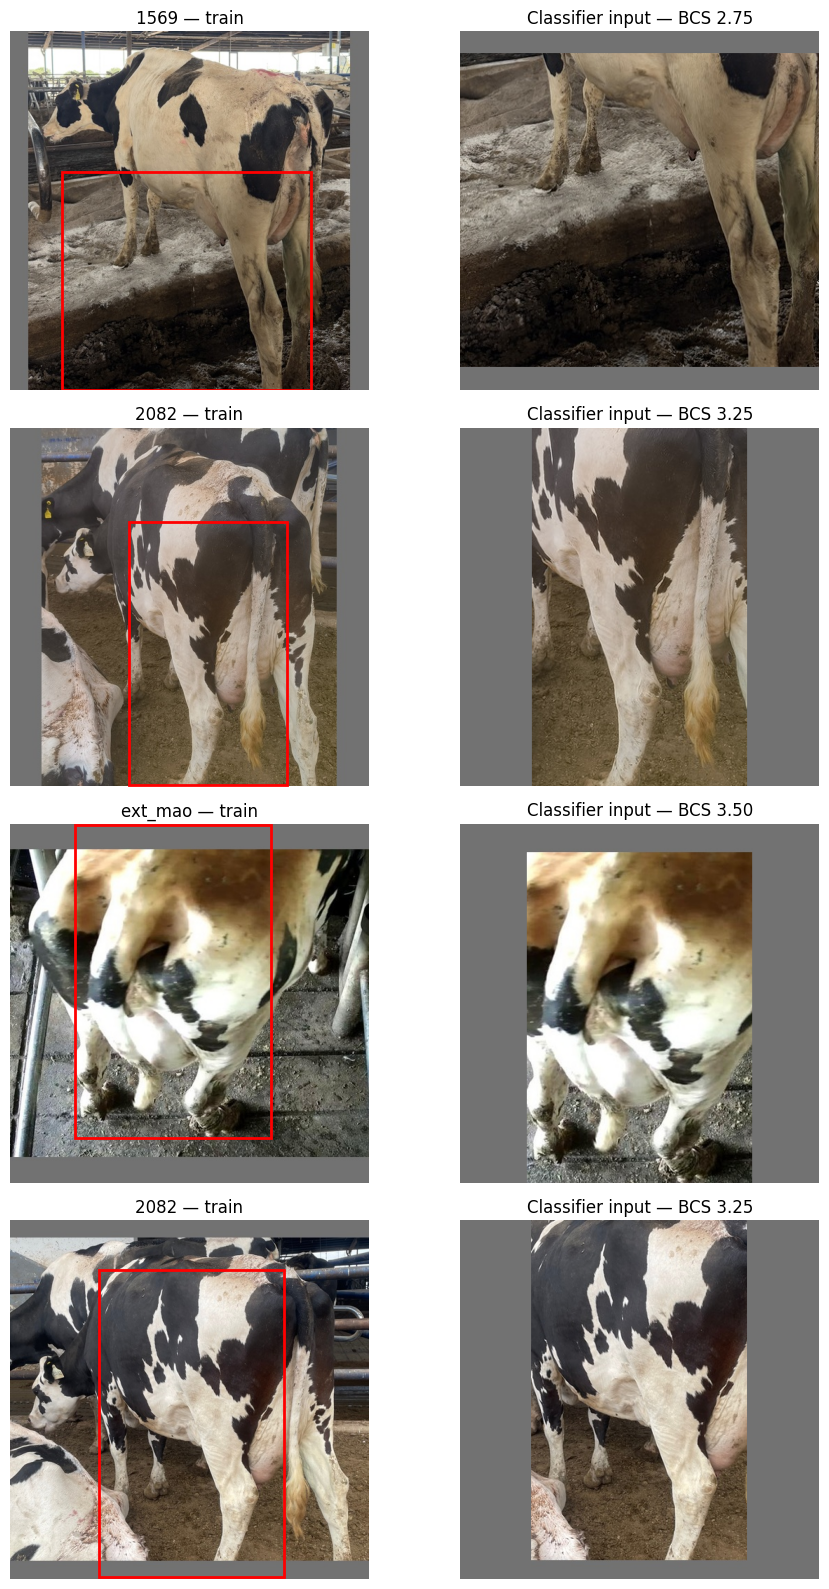

In [5]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

sample = manifest.sample(min(4, len(manifest)), random_state=42)

fig, axes = plt.subplots(len(sample), 2, figsize=(10, 4 * len(sample)))
axes = np.asarray(axes).reshape(-1, 2)

for axes_row, (_, row) in zip(axes, sample.iterrows()):
    image = Image.open(row["image"]).convert("RGB")
    x1, y1, x2, y2 = pixel_box(read_box(row["label"]), image.size)

    axes_row[0].imshow(image)
    axes_row[0].add_patch(patches.Rectangle(
        (x1, y1), x2 - x1, y2 - y1,
        fill=False, edgecolor="red", linewidth=2
    ))
    axes_row[0].set_title(f"{row['cow_id']} — {row['split']}")

    axes_row[1].imshow(square_pad(image.crop((x1, y1, x2, y2))))
    axes_row[1].set_title(f"Classifier input — BCS {row['bcs']:.2f}")

    for ax in axes_row:
        ax.axis("off")

plt.tight_layout()
plt.show()

In [6]:
# Reuse an existing detector for this fold instead of training it again.
detector_path = RESULTS / f"detector_fold_{VAL_FOLD}" / "weights" / "best.pt"
if detector_path.is_file():
    detector = YOLO(str(detector_path))
    print("Loaded existing detector:", detector_path)
else:
    detector = YOLO("yolo26s.pt")

    detector.train(
        data=str(DET / "data.yaml"),
        epochs=60,
        imgsz=640,
        batch=8,
        patience=15,
        device=DEVICE,
        workers=2,
        seed=42,
        project=str(RESULTS),
        name=f"detector_fold_{VAL_FOLD}",
    )

    detector_path = Path(detector.trainer.best)
    detector = YOLO(str(detector_path))

    shutil.copy2(
        WORK / "manifest.csv",
        detector_path.parent.parent / "manifest.csv"
    )


Loaded existing detector: /content/drive/MyDrive/lecheros/Dataset/bcs_training/detector_fold_3/weights/best.pt


In [7]:
from pathlib import Path
from datetime import datetime

run_directory = RESULTS / f"classifier_fold_{VAL_FOLD}"

if run_directory.exists() and not (run_directory / "weights/best.pt").is_file():
    backup = run_directory.with_name(
        f"{run_directory.name}_backup_{datetime.now():%Y%m%d_%H%M%S_%f}"
    )
    run_directory.rename(backup)
    print("Previous folder preserved at:", backup)

Previous folder preserved at: /content/drive/MyDrive/lecheros/Dataset/bcs_training/classifier_fold_3_backup_20261105_015130_235782


In [8]:
# Train the BCS classifier on the prepared, expert-labeled cow crops.
# Change VAL_FOLD in the first cell to train each of the five folds.
train_counts = {
    folder.name: len(list(folder.glob("*.jpg")))
    for folder in sorted((CLS / "train").iterdir()) if folder.is_dir()
}
val_counts = {
    folder.name: len(list(folder.glob("*.jpg")))
    for folder in sorted((CLS / "val").iterdir()) if folder.is_dir()
}
print("Training images per BCS:", train_counts)
print("Validation images per BCS:", val_counts)
missing = [name for name, count in val_counts.items()
           if count > 0 and train_counts.get(name, 0) == 0]
if missing:
    raise ValueError(f"Validation classes without training examples: {missing}")
if sum(count > 0 for count in train_counts.values()) < 2:
    raise ValueError("At least two populated training BCS classes are required.")

classifier_path = RESULTS / f"classifier_fold_{VAL_FOLD}" / "weights" / "best.pt"
if classifier_path.is_file():
    classifier = YOLO(str(classifier_path))
    print("Loaded existing BCS classifier:", classifier_path)
else:
    run_directory = classifier_path.parent.parent
    if run_directory.exists():
        raise FileExistsError(
            f"Incomplete run exists at {run_directory}. Rename it before restarting training."
        )
    classifier = YOLO("yolo26s-cls.pt")
    classifier.train(
        data=str(CLS),
        epochs=60,
        imgsz=224,
        batch=8,
        patience=15,
        device=DEVICE,
        workers=2,
        seed=42,
        project=str(RESULTS),
        name=f"classifier_fold_{VAL_FOLD}",
    )
    classifier_path = Path(classifier.trainer.best)
    shutil.copy2(WORK / "manifest.csv", classifier_path.parent.parent / "manifest.csv")
    classifier = YOLO(str(classifier_path))
    with open(classifier_path.parent.parent / "bcs_class_mapping.json", "w") as file:
        json.dump(classifier.names, file, indent=2)

print("Detector weights:", detector_path)
print("BCS classifier weights:", classifier_path)
print("BCS class mapping:", classifier.names)


Training images per BCS: {'2.25': 4, '2.50': 22, '2.75': 72, '3.00': 27, '3.25': 75, '3.50': 74, '3.75': 27}
Validation images per BCS: {'2.25': 0, '2.50': 0, '2.75': 12, '3.00': 0, '3.25': 15, '3.50': 4, '3.75': 0}
Ultralytics 8.4.202 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/tmp/bcs_fold3_vqknym4i/classification, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=224, iou=0.7, 